# Chapitre 4 - Cours 4 : modes de flux de données, le cas des bases de données

Les cours 1 à 3 ont comparé des formats. Mais la compatibilité est une **relation entre
deux processus** : celui qui encode et celui qui décode. Qui sont-ils ? Cela dépend de la
façon dont les données circulent. Ce cours ouvre la section *Modes of Dataflow* et traite
le premier mode, la base de données (*Dataflow Through Databases*, avec *Different values
written at different times* et *Archival storage*).

**Plan.**

1. Qui encode, qui décode ? Les modes de flux de données.
2. La base de données, un message à son futur soi.
3. Les données survivent au code : des valeurs écrites à des époques différentes.
4. Migrer sans réécrire, ou réécrire sans interrompre.
5. L'archivage : un instantané encodé avec le dernier schéma.

In [1]:
import json
import os
import sqlite3
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle, SEQ)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)
TMP = tempfile.mkdtemp(prefix="ddia_ch05_")

## 1. Qui encode, qui décode ? (section *Modes of Dataflow*)

Dès que des données quittent un processus (vers un fichier, le réseau, une base), il faut
les encoder ; un autre processus, ou le même plus tard, les décode. La compatibilité
ascendante et descendante sert l'**évolutivité** : pouvoir mettre à jour les parties d'un
système indépendamment, au lieu de tout changer d'un coup. Le livre passe en revue les
grandes façons dont les données circulent :

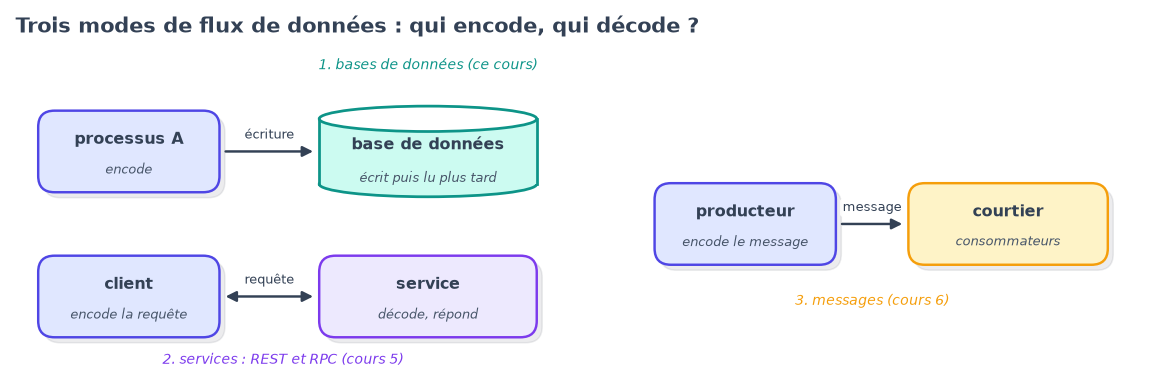

In [2]:
d = Diagram(12.5, 3.4, title="Trois modes de flux de données : qui encode, qui décode ?")
d.box("w", 1.3, 2.4, "processus A", sub="encode", color=INDIGO, w=2.0)
d.box("db", 4.6, 2.4, "base de données", sub="écrit puis lu plus tard", color=TEAL, kind="db", w=2.4, h=1.0)
d.box("c", 1.3, 0.8, "client", sub="encode la requête", color=INDIGO, w=2.0)
d.box("s", 4.6, 0.8, "service", sub="décode, répond", color=VIOLET, w=2.4)
d.box("p", 8.1, 1.6, "producteur", sub="encode le message", color=INDIGO, w=2.0)
d.box("b", 11.0, 1.6, "courtier", sub="consommateurs", color=AMBER, w=2.2)
d.arrow("w", "db", "écriture")
d.arrow("c", "s", "requête", both=True)
d.arrow("p", "b", "message")
d.note(4.6, 3.35, "1. bases de données (ce cours)", color=TEAL)
d.note(3.0, 0.1, "2. services : REST et RPC (cours 5)", color=VIOLET)
d.note(9.5, 0.75, "3. messages (cours 6)", color=AMBER)
d.show()

> **À retenir.** La compatibilité relie toujours un encodeur et un décodeur ; pour savoir
> laquelle il faut, on se demande qui écrit, qui lit, et avec quelles versions du code.

## 2. La base de données, un message à son futur soi (section *Dataflow Through Databases*)

Dans une base, le processus qui écrit encode et celui qui lit décode. S'il n'y a qu'un
processus, le lecteur est simplement une version **plus récente** du même programme :
stocker, c'est envoyer un message à son futur soi. La **compatibilité descendante** est
alors indispensable : sinon, le futur soi ne sait pas relire ce qu'il a écrit.

Mais en général plusieurs processus accèdent à la base en même temps : des applications
différentes, ou plusieurs instances d'un même service. Pendant un déploiement progressif,
certaines exécutent le nouveau code et d'autres l'ancien. Une valeur peut donc être
écrite par le nouveau code puis lue par l'ancien : la **compatibilité ascendante** est
souvent nécessaire aussi.

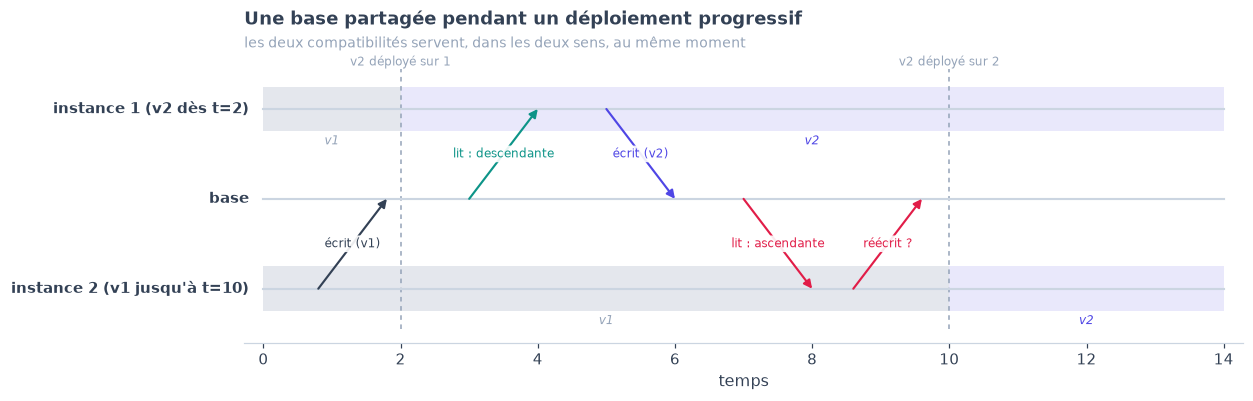

In [3]:
st = SpaceTime(["instance 1 (v2 dès t=2)", "base", "instance 2 (v1 jusqu'à t=10)"], t_max=14, width=11.5,
               title="Une base partagée pendant un déploiement progressif",
               subtitle="les deux compatibilités servent, dans les deux sens, au même moment")
st.span("instance 1 (v2 dès t=2)", 0, 2, "v1", color=GRAY)
st.span("instance 1 (v2 dès t=2)", 2, 14, "v2", color=INDIGO, alpha=0.12)
st.span("instance 2 (v1 jusqu'à t=10)", 0, 10, "v1", color=GRAY)
st.span("instance 2 (v1 jusqu'à t=10)", 10, 14, "v2", color=INDIGO, alpha=0.12)
st.msg("instance 2 (v1 jusqu'à t=10)", 0.8, "base", 1.8, "écrit (v1)", color=SLATE)
st.msg("base", 3.0, "instance 1 (v2 dès t=2)", 4.0, "lit : descendante", color=TEAL)
st.msg("instance 1 (v2 dès t=2)", 5.0, "base", 6.0, "écrit (v2)", color=INDIGO)
st.msg("base", 7.0, "instance 2 (v1 jusqu'à t=10)", 8.0, "lit : ascendante", color=ROSE)
st.msg("instance 2 (v1 jusqu'à t=10)", 8.6, "base", 9.6, "réécrit ?", color=ROSE)
st.vline(2, "v2 déployé sur 1"); st.vline(10, "v2 déployé sur 2")
st.show()

La réécriture par une instance v1 (à droite) pose à nouveau le problème des champs
inconnus (cours 1 et 2). Le format peut les préserver, mais le code applicatif doit
suivre. Avec une base relationnelle, le piège se cache souvent dans une colonne JSON :
relire le document dans un objet du modèle, le modifier et le réécrire en entier efface
les clés que l'objet ignore ; demander à la base de modifier **seulement** la clé voulue
les préserve. Démonstration avec les fonctions JSON de SQLite.

In [4]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE profils (id INTEGER PRIMARY KEY, doc TEXT)")
doc_v2 = {"nom": "Ana", "ville": "Lyon", "photo": "ana.jpg"}            # écrit par v2
con.execute("INSERT INTO profils VALUES (1, ?), (2, ?)", (json.dumps(doc_v2), json.dumps(doc_v2)))

class ProfilV1:                                     # le modèle de l'ancien code
    def __init__(self, d):
        self.nom, self.ville = d["nom"], d["ville"]
    def to_json(self):
        return json.dumps({"nom": self.nom, "ville": self.ville})

# (a) lecture-modification-écriture via le modèle v1
p = ProfilV1(json.loads(con.execute("SELECT doc FROM profils WHERE id = 1").fetchone()[0]))
p.ville = "Paris"
con.execute("UPDATE profils SET doc = ? WHERE id = 1", (p.to_json(),))
# (b) mise à jour ciblée d'une seule clé, faite par la base
con.execute("UPDATE profils SET doc = json_set(doc, '$.ville', 'Paris') WHERE id = 2")
pd.DataFrame(con.execute("SELECT id, doc FROM profils").fetchall(), columns=["id", "document après la mise à jour par v1"])

,id,document après la mise à jour par v1
0,1,"{""nom"": ""Ana"", ""ville"": ""Paris""}"
1,2,"{""nom"":""Ana"",""ville"":""Paris"",""photo"":""ana.jpg""}"


Même intention (changer la ville), deux résultats : la photo a disparu dans le premier
cas. Le livre conseille d'y penser au niveau applicatif ; ce n'est pas difficile, mais il
faut en avoir conscience.

> **À retenir.** Une base partagée exige la compatibilité descendante (le futur relit le
> passé) et, pendant les déploiements, ascendante (l'ancien code lit des valeurs
> nouvelles). Le code applicatif doit éviter d'effacer ce qu'il ne comprend pas.